# Laboratorio 4 · Análisis exploratorio de datos

**Universidad Técnica Nacional · Minería de Datos · ISW-911**

**Integrante del grupo — Ignacio Araya**

**Archivo de entrega — lab4_IC2025.ipynb**

Se estudian los accidentes de tránsito con víctimas registrados por COSEVI en Costa Rica
durante 2020-2025. El propósito es describir su calidad, preparar las variables y proponer
un modelo que clasifique la gravedad de un accidente a partir de sus características.

La unidad de observación es un accidente con víctimas. La clase distingue
**Solo heridos leves** de **Con muertos o graves**.

## 1-3. Fuente abierta y lectura desde Git

Se utiliza el consolidado de accidentes de tránsito con víctimas de COSEVI,
descargado el 18 de noviembre de 2026. El portal publica una licencia ODC-PDDL.
La copia completa se conserva en un repositorio público para la revisión docente.

- [Ficha oficial y descarga de COSEVI](https://datosabiertos.csv.go.cr/datasets/193472/consolidado-de-accidentes-de-transito-con-victimas/).
- [Repositorio público del ejercicio](https://github.com/nachoar24/workshop-4-mineria-datos).
- [CSV en el commit utilizado](https://raw.githubusercontent.com/nachoar24/workshop-4-mineria-datos/a487b47d86fdbd35a8951dc1ebbadbe01e0f0845/datos/accidentes_cosevi_2020_2025.csv).

El nombre del recurso en el portal contiene «UTF8», pero sus bytes corresponden a
**Windows-1252**. Se lee con esa codificación y separador punto y coma.
Se comprueba la huella SHA-256 para asegurar que el análisis usa los bytes originales.

In [1]:
# Laboratorio 4 de Minería de Datos. Integrante: Ignacio Araya.
# Ejecutar todas las celdas en orden en un kernel de Python.
import hashlib
import io
import re
import unicodedata
import urllib.request
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

%matplotlib inline
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 25)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})
AZUL = "#25798c"
NARANJA = "#c77735"
print("Versiones", pd.__version__, np.__version__, matplotlib.__version__, sklearn.__version__)

Versiones 3.0.1 2.5.5 3.11.2 1.9.1


In [2]:
URL_DATOS_GIT = 'https://raw.githubusercontent.com/nachoar24/workshop-4-mineria-datos/a487b47d86fdbd35a8951dc1ebbadbe01e0f0845/datos/accidentes_cosevi_2020_2025.csv'
SHA256_ESPERADO = '63cd529d8ec47c3cfc12e372fc70d28c7875fdfca90f3d7fca0ffc3cad291e81'

peticion = urllib.request.Request(URL_DATOS_GIT, headers={"User-Agent": "Workshop4-UTN"})
with urllib.request.urlopen(peticion, timeout=90) as respuesta:
    contenido_csv = respuesta.read()
assert hashlib.sha256(contenido_csv).hexdigest() == SHA256_ESPERADO

datos_originales = pd.read_csv(io.BytesIO(contenido_csv), sep=";", encoding="cp1252")
print("Lectura desde GitHub completada. Dimensiones", datos_originales.shape)
print("Huella SHA-256", hashlib.sha256(contenido_csv).hexdigest())

Lectura desde GitHub completada. Dimensiones (93699, 21)
Huella SHA-256 63cd529d8ec47c3cfc12e372fc70d28c7875fdfca90f3d7fca0ffc3cad291e81


## 4. Características principales del conjunto

Se revisan dimensiones, primeras y últimas filas, una muestra reproducible,
tipos, estadísticos descriptivos, categorías y filas con los mismos atributos.
El archivo carece de un identificador único de accidente, por lo que dos registros
iguales en estas columnas pueden representar hechos distintos.

In [3]:
print("Filas y columnas", datos_originales.shape)
display(datos_originales.head(5))
display(datos_originales.tail(3))
display(datos_originales.sample(3, random_state=42))
datos_originales.info()
display(datos_originales.describe(include="all").T)
display(pd.DataFrame({
    "tipo_original": datos_originales.dtypes.astype(str),
    "valores_distintos": datos_originales.nunique(),
}))
print("Filas repetidas en todos sus atributos", datos_originales.duplicated().sum())

Filas y columnas (93699, 21)


,Clase de accidente,Tipo de accidente,Año,Hora,Hora recodificada,Provincia,Cantón,Distrito,Ruta,Kilómetro,Rural o urbano,Calzada vertical,Calzada horizontal,Tipo de calzada,Tipo de circulación,Estado del tiempo,Estado de la calzada,Región Mideplan,Tipo ruta,Día,Mes
0,Solo heridos leves,Salió de la vía,2024,20:00-20:59,18:00-23:59,Limón,Pococí,Guápiles,32,43,Rural,Pendiente,Curva,Asfalto,Lateral igual sentido,Lluvia,Resbaladiza,Huetar caribe,Nacional,7.Sábado,D. Abril
1,Solo heridos leves,Colisión con motocicleta,2024,06:00-06:59,06:00-11:59,Heredia,San Isidro,San José,32,12,Urbana,Plano,Recta,Asfalto,Angulo recto,Buen tiempo,Buena,Central,Nacional,3.Martes,E. Mayo
2,Con muertos o graves,Vuelco,2024,15:00-15:59,12:00-17:59,San José,Vázquez de Coronado,Dulce Nombre de Jesús,32,21,Rural,Pendiente,Curva,Asfalto,Lateral igual sentido,Buen tiempo,Buena,Central,Nacional,6.Viernes,E. Mayo
3,Solo heridos leves,Colisión entre vehículos,2024,08:00-08:59,06:00-11:59,Heredia,Santo Domingo,San Miguel,32,7,Urbana,Plano,Recta,Asfalto,Por detrás,Buen tiempo,Buena,Central,Nacional,3.Martes,G. Julio
4,Solo heridos leves,Colisión con motocicleta,2024,07:00-07:59,06:00-11:59,Heredia,Santo Domingo,San Miguel,32,5,Urbana,Plano,Recta,Asfalto,Lateral igual sentido,Buen tiempo,Buena,Central,Nacional,3.Martes,H. Agosto


,Clase de accidente,Tipo de accidente,Año,Hora,Hora recodificada,Provincia,Cantón,Distrito,Ruta,Kilómetro,Rural o urbano,Calzada vertical,Calzada horizontal,Tipo de calzada,Tipo de circulación,Estado del tiempo,Estado de la calzada,Región Mideplan,Tipo ruta,Día,Mes
93696,Solo heridos leves,Colisión entre vehículos,2025,08:00-08:59,06:00-11:59,San José,Montes de Oca,San Pedro,Cantonal,Cantonal,Urbana,Plano,Recta,Asfalto,Lateral igual sentido,Buen tiempo,Buena,Central,Cantonal,6.Viernes,L. Diciembre
93697,Solo heridos leves,Colisión entre vehículos,2025,08:00-08:59,06:00-11:59,Alajuela,Atenas,Concepción,27,32,Urbana,Plano,Recta,Asfalto,Por detrás,Lluvia,Buena,Central,Nacional,2.Lunes,J. Octubre
93698,Solo heridos leves,Colisión con motocicleta,2025,09:00-09:59,06:00-11:59,Alajuela,Alajuela,San Rafael,Ignorada,Ignorado,Desconocida,Plano,Recta,Asfalto,Lateral igual sentido,Buen tiempo,Buena,Desconocida,Ignorada,4.Miércoles,L. Diciembre


,Clase de accidente,Tipo de accidente,Año,Hora,Hora recodificada,Provincia,Cantón,Distrito,Ruta,Kilómetro,Rural o urbano,Calzada vertical,Calzada horizontal,Tipo de calzada,Tipo de circulación,Estado del tiempo,Estado de la calzada,Región Mideplan,Tipo ruta,Día,Mes
33315,Solo heridos leves,Atropello a persona,2023,13:00-13:59,12:00-17:59,Cartago,Paraíso,Paraíso,Cantonal,Cantonal,Urbana,Pendiente,Recta,Asfalto,De frente,Buen tiempo,Buena,Central,Cantonal,5.Jueves,H. Agosto
77374,Solo heridos leves,Colisión con motocicleta,2025,20:00-20:59,18:00-23:59,Guanacaste,Santa Cruz,Cartagena,155,15,Rural,Plano,Recta,Asfalto,Por detrás,Buen tiempo,Buena,Chorotega,Nacional,2.Lunes,B. Febrero
42418,Con muertos o graves,Salió de la vía,2022,01:00-01:59,00:00-05:59,Limón,Limón,Río Blanco,32,137,Rural,Plano,Recta,Asfalto,De frente,Buen tiempo,Buena,Huetar caribe,Nacional,1.Domingo,B. Febrero


<class 'pandas.DataFrame'>
RangeIndex: 93699 entries, 0 to 93698
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Clase de accidente    93699 non-null  str  
 1   Tipo de accidente     93699 non-null  str  
 2   Año                   93699 non-null  int64
 3   Hora                  93699 non-null  str  
 4   Hora recodificada     93699 non-null  str  
 5   Provincia             93699 non-null  str  
 6   Cantón                93699 non-null  str  
 7   Distrito              93699 non-null  str  
 8   Ruta                  93699 non-null  str  
 9   Kilómetro             93699 non-null  str  
 10  Rural o urbano        93699 non-null  str  
 11  Calzada vertical      93699 non-null  str  
 12  Calzada horizontal    93699 non-null  str  
 13  Tipo de calzada       93699 non-null  str  
 14  Tipo de circulación   93699 non-null  str  
 15  Estado del tiempo     93699 non-null  str  
 16  Estado de la ca

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Clase de accidente,93699,2,Solo heridos leves,80303,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tipo de accidente,93699,12,Colisión con motocicleta,39459,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Año,93699.0,NaN,NaN,NaN,2022.72845,1.672523,2020.0,2021.0,2023.0,2024.0,2025.0
Hora,93699,24,18:00-18:59,6213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hora recodificada,93699,4,12:00-17:59,31341,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Provincia,93699,7,San José,32206,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cantón,93699,84,San José,10512,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distrito,93699,396,San Rafael,3033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ruta,93699,331,Cantonal,29117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kilómetro,93699,349,Cantonal,29117,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,tipo_original,valores_distintos
Clase de accidente,str,2
Tipo de accidente,str,12
Año,int64,6
Hora,str,24
Hora recodificada,str,4
Provincia,str,7
Cantón,str,84
Distrito,str,396
Ruta,str,331
Kilómetro,str,349


Filas repetidas en todos sus atributos 73


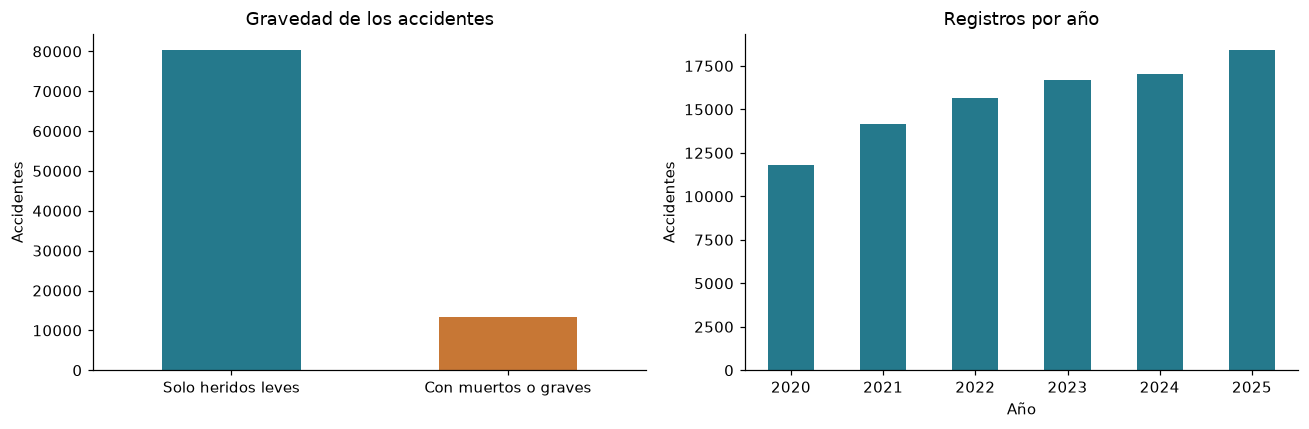

Clase de accidente
Solo heridos leves      85.7
Con muertos o graves    14.3
Name: porcentaje, dtype: float64

In [4]:
frecuencias_clase = datos_originales["Clase de accidente"].value_counts()
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
frecuencias_clase.plot.bar(ax=ejes[0], color=[AZUL, NARANJA], rot=0)
ejes[0].set(title="Gravedad de los accidentes", xlabel="", ylabel="Accidentes")
datos_originales["Año"].value_counts().sort_index().plot.bar(ax=ejes[1], color=AZUL, rot=0)
ejes[1].set(title="Registros por año", xlabel="Año", ylabel="Accidentes")
fig.tight_layout()
plt.show()
display((frecuencias_clase / len(datos_originales) * 100).rename("porcentaje").round(2))

## 5. Nombres de columnas en español

Los encabezados de origen ya están en español. Se renombran con términos en español,
sin espacios sobrantes ni tildes y con guiones bajos para facilitar su uso en Python.
La tabla siguiente documenta cada cambio.

In [5]:
nombres_espanol = {
    "Clase de accidente": "clase_accidente",
    "Tipo de accidente": "tipo_accidente",
    "Año": "ano",
    "Hora": "intervalo_hora",
    "Hora recodificada": "franja_horaria",
    "Provincia": "provincia",
    "Cantón": "canton",
    "Distrito": "distrito",
    "Ruta": "ruta",
    "Kilómetro": "kilometro",
    "Rural o urbano": "zona",
    "Calzada vertical": "calzada_vertical",
    "Calzada horizontal": "calzada_horizontal",
    "Tipo de calzada": "tipo_calzada",
    "Tipo de circulación": "tipo_circulacion",
    "Estado del tiempo": "estado_tiempo",
    "Estado de la calzada": "estado_calzada",
    "Región Mideplan": "region_mideplan",
    "Tipo ruta": "tipo_ruta",
    "Día": "dia_semana_texto",
    "Mes": "mes_texto",
}
renombrar = {nombre: nombres_espanol[nombre.strip()] for nombre in datos_originales.columns}
display(pd.DataFrame(renombrar.items(), columns=["nombre_original", "nombre_espanol"]))
datos = datos_originales.rename(columns=renombrar).copy()
assert datos.columns.is_unique
columnas_texto = datos.columns.drop("ano")
datos[columnas_texto] = datos[columnas_texto].apply(lambda serie: serie.astype("string").str.strip())

,nombre_original,nombre_espanol
0,Clase de accidente,clase_accidente
1,Tipo de accidente,tipo_accidente
2,Año,ano
3,Hora,intervalo_hora
4,Hora recodificada,franja_horaria
5,Provincia,provincia
6,Cantón,canton
7,Distrito,distrito
8,Ruta,ruta
9,Kilómetro,kilometro


## 6. Valores nulos y ausencia de información

Se distinguen tres situaciones en la evidencia gráfica.

- Las celdas vacías reconocidas por pandas.
- Los valores «Desconocido», «Desconocida», «Ignorado» e «Ignorada», que indican
  información ausente aunque estén escritos como texto.
- «Cantonal» en kilómetro, que corresponde a una referencia kilométrica no aplicable.

Los marcadores de desconocimiento se convierten a nulos. «Cantonal» se conserva como
categoría legítima de ruta y se identifica con un indicador independiente para kilómetro.

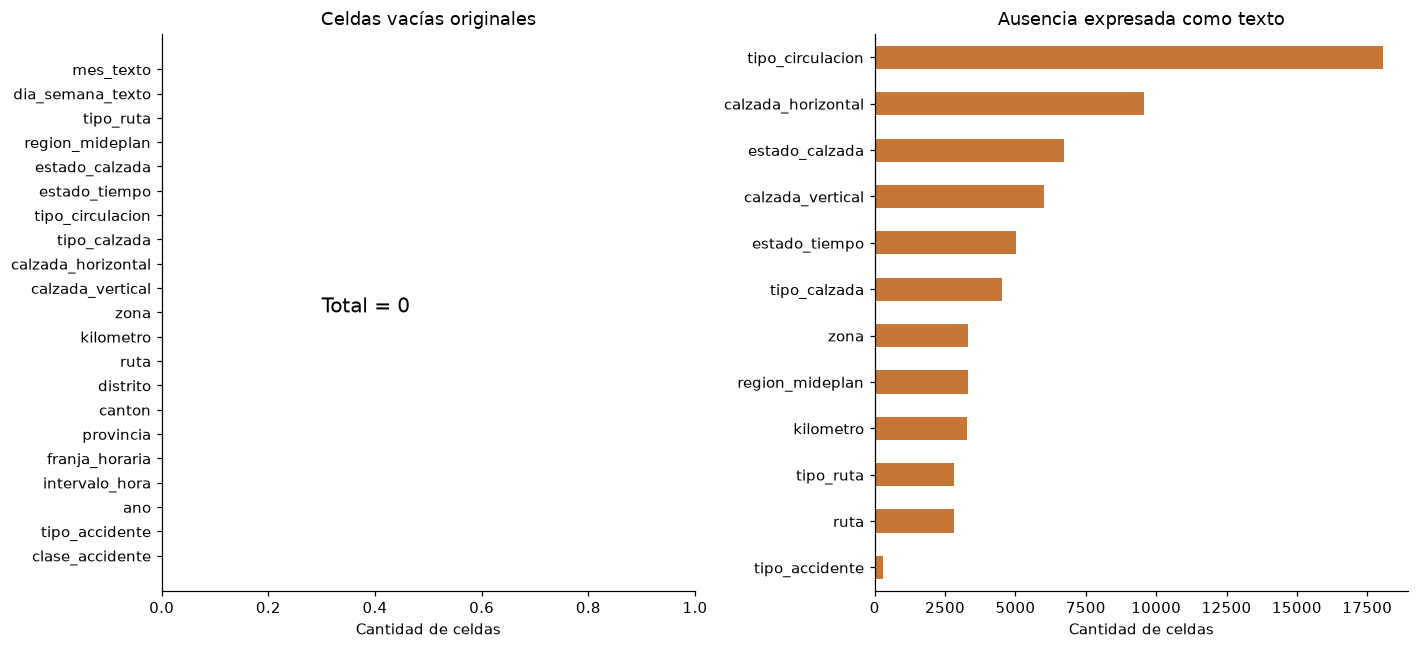

,nulos_originales,marcadores_desconocidos
clase_accidente,0,0
tipo_accidente,0,294
ano,0,0
intervalo_hora,0,0
franja_horaria,0,0
provincia,0,0
canton,0,0
distrito,0,0
ruta,0,2802
kilometro,0,3282


Kilómetro no aplicable en ruta cantonal 29117
Total de marcadores reconocidos como nulos 65759


In [6]:
nulos_originales = datos.isna().sum()
marcadores = ["desconocido", "desconocida", "ignorado", "ignorada"]
desconocidos = pd.DataFrame(False, index=datos.index, columns=datos.columns)
for columna in columnas_texto:
    desconocidos[columna] = datos[columna].str.casefold().isin(marcadores)
kilometro_no_aplica = datos["kilometro"].eq("Cantonal").fillna(False)

informe_nulos = pd.DataFrame({
    "nulos_originales": nulos_originales,
    "marcadores_desconocidos": desconocidos.sum(),
})
fig, ejes = plt.subplots(1, 2, figsize=(13, 6))
ejes[0].barh(informe_nulos.index, informe_nulos["nulos_originales"], color=AZUL)
ejes[0].set(title="Celdas vacías originales", xlabel="Cantidad de celdas", xlim=(0, 1))
ejes[0].text(0.3, 10, f"Total = {nulos_originales.sum()}", fontsize=13)
ausentes = informe_nulos["marcadores_desconocidos"].loc[lambda s: s > 0].sort_values()
ausentes.plot.barh(ax=ejes[1], color=NARANJA)
ejes[1].set(title="Ausencia expresada como texto", xlabel="Cantidad de celdas")
fig.tight_layout()
plt.show()
display(informe_nulos)
print("Kilómetro no aplicable en ruta cantonal", int(kilometro_no_aplica.sum()))

for columna in columnas_texto:
    datos.loc[desconocidos[columna], columna] = pd.NA
datos["kilometro_no_aplica"] = kilometro_no_aplica.astype("uint8")
datos["kilometro_imputado"] = (datos["kilometro"].isna() & ~kilometro_no_aplica).astype("uint8")
columnas_originales = list(renombrar.values())
nulos_reconocidos = datos[columnas_originales].isna().sum()
print("Total de marcadores reconocidos como nulos", int(nulos_reconocidos.sum()))

## 9. Conversión de tipos para analizar las variables

Se adelanta la conversión necesaria para evaluar los atípicos numéricos del punto 7.
El año es un entero, la hora corresponde al inicio del intervalo registrado y
el día es un **día de la semana**, con domingo = 1 y sábado = 7.
El mes se traduce del prefijo A-L a los valores 1-12.
Estas columnas no incluyen día del mes para construir una fecha completa.

Ruta se conserva como etiqueta porque sus códigos identifican carreteras.
Kilómetro se convierte a número y la referencia cantonal se representa temporalmente
como nula, junto con su indicador de no aplicabilidad.

In [7]:
datos["ano"] = pd.to_numeric(datos["ano"], errors="raise").astype("int16")
datos["hora_inicio"] = datos["intervalo_hora"].str.slice(0, 2).astype("int8")
datos["dia_semana"] = datos["dia_semana_texto"].str.split(".").str[0].astype("int8")
mapa_meses = {letra: numero for numero, letra in enumerate("ABCDEFGHIJKL", start=1)}
datos["mes"] = datos["mes_texto"].str[0].map(mapa_meses).astype("int8")
datos["kilometro"] = pd.to_numeric(
    datos["kilometro"].mask(kilometro_no_aplica), errors="raise"
).astype("float64")
assert datos["hora_inicio"].between(0, 23).all()
assert datos["dia_semana"].between(1, 7).all()
assert datos["mes"].between(1, 12).all()
assert datos["kilometro"].dropna().ge(0).all()
display(datos[["ano", "hora_inicio", "dia_semana", "mes", "kilometro", "ruta"]].dtypes.to_frame("tipo"))

,tipo
ano,int16
hora_inicio,int8
dia_semana,int8
mes,int8
kilometro,float64
ruta,string


## 7. Detección de valores atípicos

Se usa la regla de Tukey sobre los kilómetros observados. Se marca como atípico
un valor fuera de Q1 − 1,5 × IQR y Q3 + 1,5 × IQR. Año, mes, día y hora tienen
dominios discretos que se validaron en la celda anterior.

El kilómetro depende del origen de cada carretera. Al reunir rutas distintas pueden
aparecer valores altos válidos. Se conservarán los registros señalados por IQR,
pues el archivo no demuestra que sean errores. La marca queda en el dataset procesado.

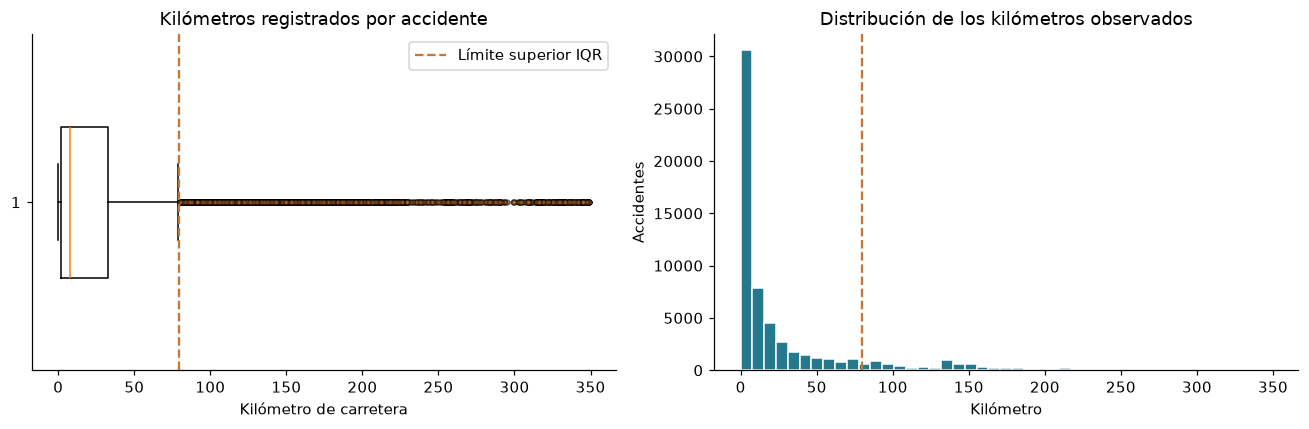

Límites IQR [-44.50, 79.50]
Señalados 8,136 de 61,300 observados (13.27 %)


,ruta,kilometro,provincia,clase_accidente
30,2,136.0,San José,Solo heridos leves
31,2,133.0,San José,Solo heridos leves
32,2,157.0,San José,Solo heridos leves
36,2,134.0,San José,Solo heridos leves
39,2,139.0,San José,Solo heridos leves
40,2,135.0,San José,Solo heridos leves
42,2,140.0,San José,Solo heridos leves
45,2,137.0,San José,Solo heridos leves
46,2,134.0,San José,Solo heridos leves
51,2,136.0,San José,Con muertos o graves


In [8]:
def detectar_atipicos_iqr(serie):
    '''Devuelve la marca y los límites de Tukey usando solo valores observados.'''
    q1, q3 = serie.dropna().quantile([0.25, 0.75])
    rango = q3 - q1
    inferior, superior = q1 - 1.5 * rango, q3 + 1.5 * rango
    marca = ((serie < inferior) | (serie > superior)).fillna(False)
    return marca, inferior, superior

marca_atipicos, limite_inferior, limite_superior = detectar_atipicos_iqr(datos["kilometro"])
datos["kilometro_atipico_iqr"] = marca_atipicos.astype("uint8")
kilometros_observados = datos["kilometro"].dropna()
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].boxplot(kilometros_observados, orientation="horizontal", widths=0.45,
               flierprops={"markersize": 3, "markerfacecolor": NARANJA, "alpha": 0.25})
ejes[0].axvline(limite_superior, color=NARANJA, linestyle="--", label="Límite superior IQR")
ejes[0].set(title="Kilómetros registrados por accidente", xlabel="Kilómetro de carretera")
ejes[0].legend()
ejes[1].hist(kilometros_observados, bins=45, color=AZUL, edgecolor="white")
ejes[1].axvline(limite_superior, color=NARANJA, linestyle="--")
ejes[1].set(title="Distribución de los kilómetros observados", xlabel="Kilómetro", ylabel="Accidentes")
fig.tight_layout()
plt.show()
porcentaje_atipicos = 100 * marca_atipicos.sum() / kilometros_observados.size
print(f"Límites IQR [{limite_inferior:.2f}, {limite_superior:.2f}]")
print(f"Señalados {marca_atipicos.sum():,} de {kilometros_observados.size:,} observados ({porcentaje_atipicos:.2f} %)")
display(datos.loc[marca_atipicos, ["ruta", "kilometro", "provincia", "clase_accidente"]].head(10))

## 8. Funciones de imputación y justificación

El enunciado menciona los puntos 5 y 6 al pedir la imputación. Se aplican las funciones
a las ausencias encontradas y se documenta el tratamiento de los atípicos del punto 7.

Para las categorías se usa **No informado**, conservando la ausencia como información
observable. Rellenarlas con la moda atribuiría condiciones de circulación o clima
que el parte no registró.

Para un kilómetro desconocido se usa primero la mediana de la misma ruta. Si la ruta
también es desconocida o carece de mediciones, se usa la mediana global de los kilómetros
observados. Es una aproximación de preprocesamiento, identificada por
`kilometro_imputado`. Para las rutas cantonales se usa el valor auxiliar 0 y
`kilometro_no_aplica = 1`, que permite distinguirlo de un kilómetro cero observado.

Los atípicos IQR conservan su valor porque pueden corresponder a carreteras largas.
Las 73 coincidencias en todos los atributos también se conservan al no existir un
identificador que confirme que son el mismo accidente.

,resultado
mediana_de_la_ruta,484.0
mediana_global,2798.0
no_aplica_valor_auxiliar,29117.0
mediana_global_km,8.0


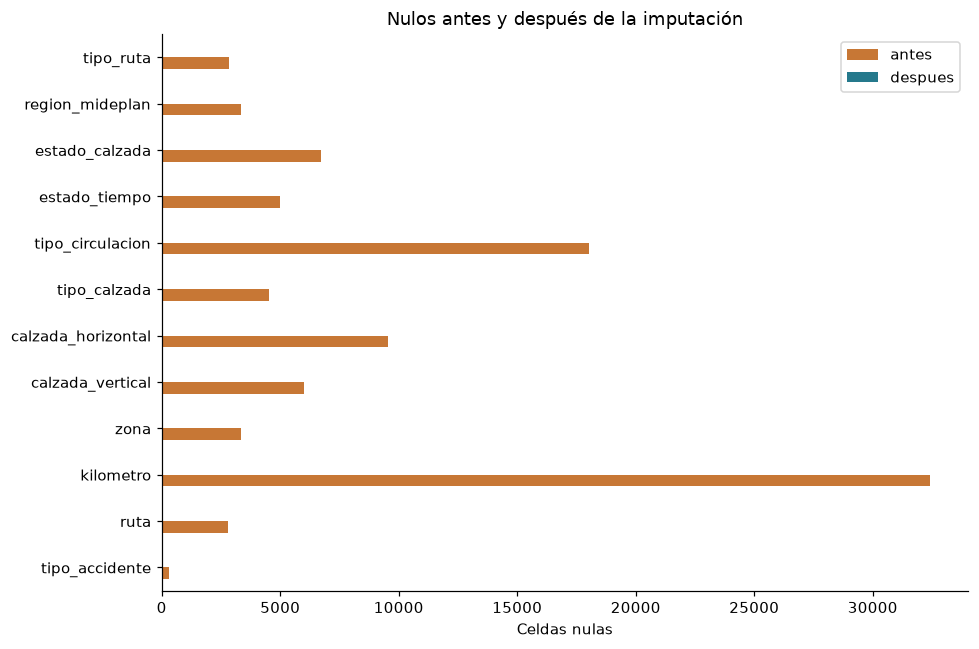

,tipo_preparado
clase_accidente,category
tipo_accidente,category
ano,int16
intervalo_hora,category
franja_horaria,category
...,...
kilometro_imputado,uint8
hora_inicio,int8
dia_semana,int8
mes,int8


In [9]:
def imputar_kilometros_por_ruta(tabla):
    '''Imputa ausencias reales por mediana y distingue referencias no aplicables.'''
    resultado = tabla.copy()
    mediana_global = resultado["kilometro"].median()
    medianas_ruta = resultado.groupby("ruta")["kilometro"].median()
    estimacion_ruta = resultado["ruta"].map(medianas_ruta)
    faltantes_reales = resultado["kilometro_imputado"].eq(1)
    usa_global = faltantes_reales & estimacion_ruta.isna()
    resultado.loc[faltantes_reales, "kilometro"] = estimacion_ruta.fillna(mediana_global)[faltantes_reales]
    resultado.loc[resultado["kilometro_no_aplica"].eq(1), "kilometro"] = 0.0
    informe = pd.Series({
        "mediana_de_la_ruta": int((faltantes_reales & ~usa_global).sum()),
        "mediana_global": int(usa_global.sum()),
        "no_aplica_valor_auxiliar": int(resultado["kilometro_no_aplica"].sum()),
        "mediana_global_km": mediana_global,
    })
    return resultado, informe

def imputar_categoricas(tabla, columnas):
    '''Conserva los desconocidos en una categoría explícita.'''
    resultado = tabla.copy()
    resultado[columnas] = resultado[columnas].fillna("No informado")
    return resultado

datos_limpios, informe_imputacion = imputar_kilometros_por_ruta(datos)
categoricas_originales = list(columnas_texto.drop("kilometro"))
datos_limpios = imputar_categoricas(datos_limpios, categoricas_originales)
for columna in categoricas_originales:
    datos_limpios[columna] = datos_limpios[columna].astype("category")

display(informe_imputacion.to_frame("resultado"))
comparacion_nulos = pd.DataFrame({
    "antes": datos[columnas_originales].isna().sum(),
    "despues": datos_limpios[columnas_originales].isna().sum(),
})
comparacion_nulos.loc[comparacion_nulos["antes"] > 0].plot.barh(
    color=[NARANJA, AZUL], figsize=(9, 6)
)
plt.title("Nulos antes y después de la imputación")
plt.xlabel("Celdas nulas")
plt.ylabel("")
plt.tight_layout()
plt.show()
assert not datos_limpios.isna().any().any()
assert len(datos_limpios) == len(datos_originales)
assert datos_limpios.loc[marca_atipicos, "kilometro"].equals(datos.loc[marca_atipicos, "kilometro"])
display(datos_limpios.dtypes.to_frame("tipo_preparado"))

## 10. Conversión de las categorías a números

La variable dependiente `accidente_grave` vale 1 cuando la clase es
**Con muertos o graves**, y 0 para **Solo heridos leves**.

Las variables nominales con pocas categorías se convierten mediante **one-hot**.
Cantón, distrito y ruta se codifican por su frecuencia relativa para evitar cientos
de indicadores en un CSV ancho. En cantón y distrito se incluye la jerarquía geográfica
al calcular las frecuencias para distinguir nombres repetidos.
Esta codificación resume la frecuencia y pierde la identidad exacta de la etiqueta,
que se conserva en el dataset original de Git.

Hora, día de la semana y mes se representan con seno y coseno por su comportamiento
cíclico. Por ejemplo, las horas 23 y 0 quedan próximas en esta representación.
La franja horaria agregada se omite al estar representada por la hora de inicio.

In [10]:
mapa_objetivo = {"Solo heridos leves": 0, "Con muertos o graves": 1}
objetivo = datos_limpios["clase_accidente"].astype("string").map(mapa_objetivo)
assert objetivo.notna().all(), "Se encontró una clase de accidente sin correspondencia."
objetivo = objetivo.astype("uint8").rename("accidente_grave")

predictores = datos_limpios[["ano", "kilometro", "kilometro_no_aplica",
                            "kilometro_imputado", "kilometro_atipico_iqr"]].copy()
for columna, periodo, inicio in [("hora_inicio", 24, 0), ("dia_semana", 7, 1), ("mes", 12, 1)]:
    angulo = 2 * np.pi * (datos_limpios[columna] - inicio) / periodo
    predictores[columna + "_seno"] = np.sin(angulo)
    predictores[columna + "_coseno"] = np.cos(angulo)

provincia = datos_limpios["provincia"].astype("string")
canton = provincia + " | " + datos_limpios["canton"].astype("string")
distrito = canton + " | " + datos_limpios["distrito"].astype("string")
etiquetas_geograficas = {"canton": canton, "distrito": distrito,
                        "ruta": datos_limpios["ruta"].astype("string")}
frecuencias_codificacion = {}
for columna, etiquetas in etiquetas_geograficas.items():
    frecuencias = etiquetas.value_counts(normalize=True)
    frecuencias_codificacion[columna] = frecuencias
    predictores[columna + "_frecuencia"] = etiquetas.map(frecuencias).astype("float64")

categoricas_modelo = ["tipo_accidente", "provincia", "zona", "calzada_vertical",
                     "calzada_horizontal", "tipo_calzada", "tipo_circulacion",
                     "estado_tiempo", "estado_calzada", "region_mideplan", "tipo_ruta"]
indicadores = pd.get_dummies(datos_limpios[categoricas_modelo], prefix_sep="__", dtype="uint8")

def nombre_numerico_espanol(nombre):
    '''Normaliza los encabezados de las categorías en español para el CSV.'''
    sin_tildes = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9_]+", "_", sin_tildes.lower()).strip("_")

indicadores.columns = [nombre_numerico_espanol(nombre) for nombre in indicadores.columns]
predictores = pd.concat([predictores, indicadores], axis=1)
assert predictores.columns.is_unique
print("Dimensiones de la matriz numérica", predictores.shape)
display(predictores.head())
display(pd.concat([objetivo.value_counts(), objetivo.value_counts(normalize=True) * 100],
                  axis=1, keys=["accidentes", "porcentaje"]).rename(
                      index={valor: clase for clase, valor in mapa_objetivo.items()}))

Dimensiones de la matriz numérica (93699, 81)


,ano,kilometro,kilometro_no_aplica,kilometro_imputado,kilometro_atipico_iqr,hora_inicio_seno,hora_inicio_coseno,dia_semana_seno,dia_semana_coseno,mes_seno,mes_coseno,canton_frecuencia,...,estado_calzada__resbaladiza,region_mideplan__brunca,region_mideplan__central,region_mideplan__chorotega,region_mideplan__huetar_caribe,region_mideplan__huetar_norte,region_mideplan__no_informado,region_mideplan__pacifico_central,tipo_ruta__cantonal,tipo_ruta__nacional,tipo_ruta__nacional_sin_coordenada,tipo_ruta__no_informado
0,2024,43.0,0,0,0,-0.866025,5.000000e-01,-0.781831,0.623490,1.000000e+00,6.123234e-17,0.027119,...,1,0,0,0,1,0,0,0,0,1,0,0
1,2024,12.0,0,0,0,1.000000,6.123234e-17,0.974928,-0.222521,8.660254e-01,-5.000000e-01,0.002305,...,0,0,1,0,0,0,0,0,0,1,0,0
2,2024,21.0,0,0,0,-0.707107,-7.071068e-01,-0.974928,-0.222521,8.660254e-01,-5.000000e-01,0.011153,...,0,0,1,0,0,0,0,0,0,1,0,0
3,2024,7.0,0,0,0,0.866025,-5.000000e-01,0.974928,-0.222521,1.224647e-16,-1.000000e+00,0.010246,...,0,0,1,0,0,0,0,0,0,1,0,0
4,2024,5.0,0,0,0,0.965926,-2.588190e-01,0.974928,-0.222521,-5.000000e-01,-8.660254e-01,0.010246,...,0,0,1,0,0,0,0,0,0,1,0,0


,accidentes,porcentaje
accidente_grave,,
Solo heridos leves,80303,85.703156
Con muertos o graves,13396,14.296844


## 11. Estandarización

Se aplica `StandardScaler` al año, kilómetro y frecuencias geográficas.
Cada columna se centra en su media y se divide por su desviación estándar poblacional.
Los indicadores binarios permanecen en 0 y 1, y las representaciones cíclicas
permanecen acotadas entre −1 y 1. La variable dependiente conserva su codificación binaria.

Los parámetros se calculan con el conjunto completo para describir este EDA.
Al evaluar un modelo predictivo, las medianas, frecuencias, categorías y escalas
deben ajustarse usando únicamente el conjunto de entrenamiento.

,media_original,escala_original,media_estandarizada,desviacion_estandarizada
ano,2022.728450,1.672515,-0.0,1.0
kilometro,21.623635,48.261922,0.0,1.0
canton_frecuencia,0.032986,0.033655,0.0,1.0
distrito_frecuencia,0.005816,0.004519,0.0,1.0
ruta_frecuencia,0.107735,0.137082,0.0,1.0


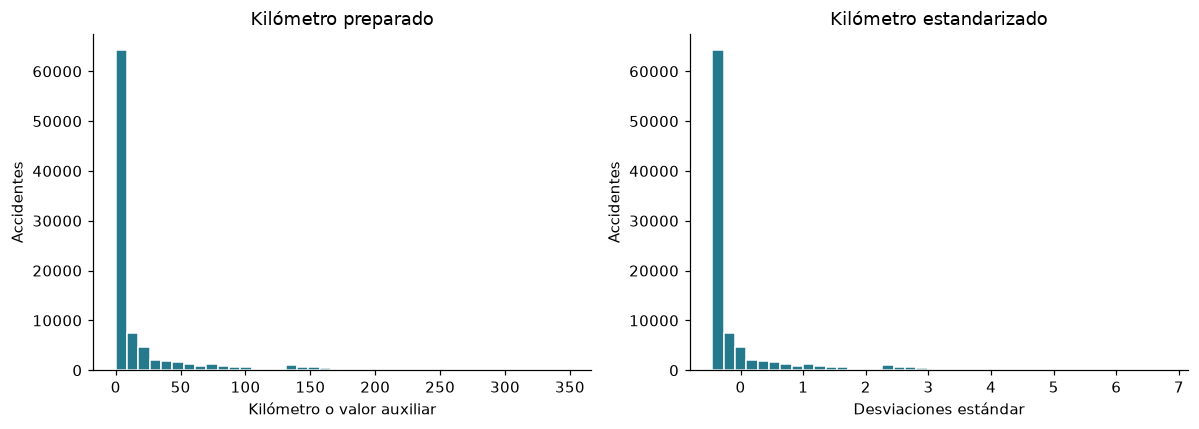

In [11]:
columnas_estandarizar = ["ano", "kilometro", "canton_frecuencia",
                        "distrito_frecuencia", "ruta_frecuencia"]
estandarizador = StandardScaler()
predictores_estandarizados = predictores.copy()
valores_estandarizados = estandarizador.fit_transform(predictores[columnas_estandarizar])
for posicion, columna in enumerate(columnas_estandarizar):
    predictores_estandarizados[columna] = valores_estandarizados[:, posicion]

parametros = pd.DataFrame({
    "media_original": estandarizador.mean_,
    "escala_original": estandarizador.scale_,
    "media_estandarizada": predictores_estandarizados[columnas_estandarizar].mean(),
    "desviacion_estandarizada": predictores_estandarizados[columnas_estandarizar].std(ddof=0),
}, index=columnas_estandarizar)
display(parametros.round(6))
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].hist(predictores["kilometro"], bins=40, color=AZUL, edgecolor="white")
ejes[0].set(title="Kilómetro preparado", xlabel="Kilómetro o valor auxiliar", ylabel="Accidentes")
ejes[1].hist(predictores_estandarizados["kilometro"], bins=40, color=AZUL, edgecolor="white")
ejes[1].set(title="Kilómetro estandarizado", xlabel="Desviaciones estándar", ylabel="Accidentes")
fig.tight_layout()
plt.show()

## 12. Correlación con evidencia gráfica

Primero se calcula Pearson entre las variables de calendario, el kilómetro observado
y el indicador de gravedad. En kilómetro se usan solo las mediciones observadas
para separar esa lectura del efecto de la imputación.
Se muestran también las asociaciones más altas con la variable dependiente
en la matriz numérica preparada. Para dos indicadores binarios, Pearson corresponde
al coeficiente phi.

Una correlación marginal describe asociación. La interpretación de hora, mes y día
debe considerar su ciclo, y la del kilómetro depende de la carretera.

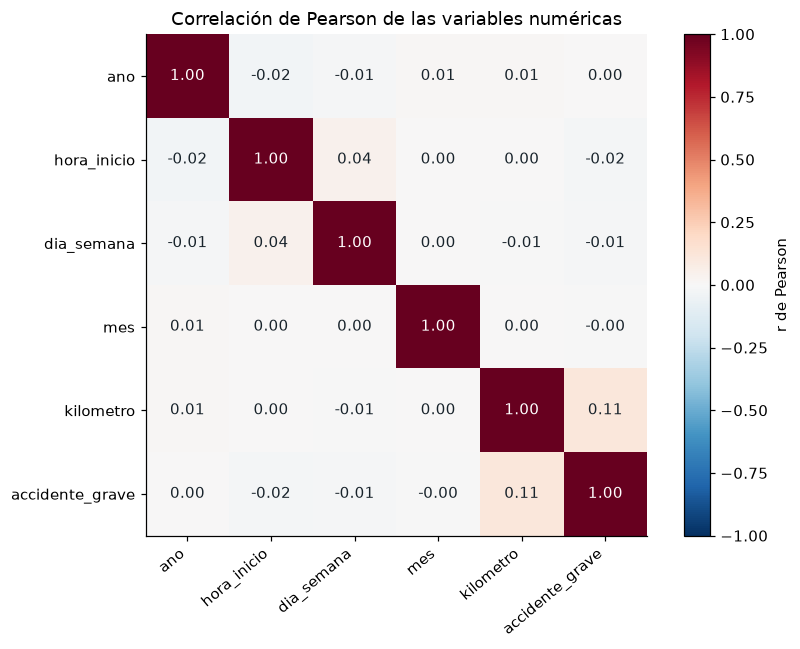

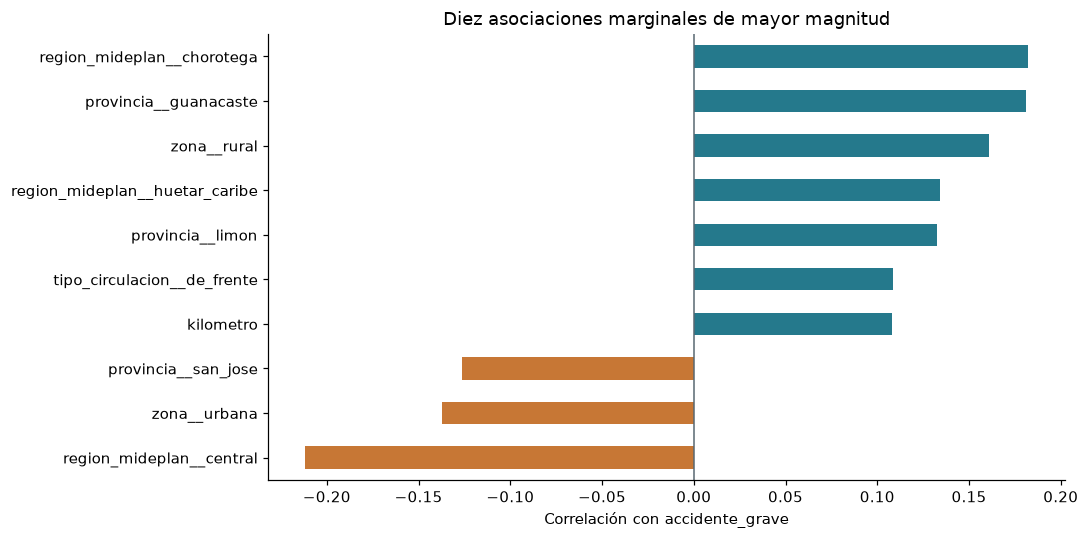

,correlacion
region_mideplan__central,-0.2121
region_mideplan__chorotega,0.1824
provincia__guanacaste,0.1812
zona__rural,0.1610
zona__urbana,-0.1373
region_mideplan__huetar_caribe,0.1340
provincia__limon,0.1324
provincia__san_jose,-0.1262
tipo_circulacion__de_frente,0.1088
kilometro,0.1078


La mayor asociación marginal corresponde a **region_mideplan__central**, con **r = -0.212**. La combinación de características puede aportar información adicional a estas asociaciones individuales.

In [12]:
correlacion_base = datos[["ano", "hora_inicio", "dia_semana", "mes", "kilometro"]].copy()
correlacion_base["accidente_grave"] = objetivo
matriz = correlacion_base.corr(method="pearson")
fig, eje = plt.subplots(figsize=(8, 6))
imagen = eje.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(matriz)), matriz.columns, rotation=40, ha="right")
eje.set_yticks(range(len(matriz)), matriz.columns)
for fila in range(len(matriz)):
    for columna in range(len(matriz)):
        valor = matriz.iloc[fila, columna]
        eje.text(columna, fila, f"{valor:.2f}", ha="center", va="center",
                 color="white" if abs(valor) > 0.55 else "#18232b")
eje.set_title("Correlación de Pearson de las variables numéricas")
fig.colorbar(imagen, ax=eje, label="r de Pearson")
fig.tight_layout()
plt.show()

correlaciones_objetivo = predictores_estandarizados.corrwith(objetivo)
principales = correlaciones_objetivo.dropna().reindex(
    correlaciones_objetivo.dropna().abs().sort_values(ascending=False).head(10).index
)
principales.sort_values().plot.barh(
    figsize=(10, 5), color=[AZUL if valor >= 0 else NARANJA for valor in principales.sort_values()]
)
plt.axvline(0, color="#596872", linewidth=1)
plt.xlabel("Correlación con accidente_grave")
plt.title("Diez asociaciones marginales de mayor magnitud")
plt.tight_layout()
plt.show()
display(principales.rename("correlacion").to_frame().round(4))
mayor = principales.index[0]
display(Markdown(f"La mayor asociación marginal corresponde a **{mayor}**, "
                 f"con **r = {principales.iloc[0]:.3f}**. "
                 "La combinación de características puede aportar información adicional "
                 "a estas asociaciones individuales."))

## 13. Variable dependiente y modelo candidato

La variable dependiente es **accidente_grave**. Su interpretación proviene directamente
de la clase publicada por COSEVI.

Se propone un **árbol de decisión de clasificación**. Puede representar interacciones
entre el tipo de accidente, la zona, las condiciones de la vía y la hora mediante
reglas interpretables. Se limita su profundidad y el tamaño mínimo de las hojas
para controlar la complejidad. El peso de clases equilibrado permite considerar
la menor frecuencia de accidentes con personas fallecidas o heridas graves.

Para una evaluación posterior se puede separar entrenamiento en 2020-2024 y prueba
en 2025, ajustar el preprocesamiento sobre entrenamiento y evaluar recall y F1 de la
clase grave, la matriz de confusión y PR-AUC. El objeto siguiente documenta la
configuración candidata. La selección y justificación del modelo completan el alcance
solicitado por el enunciado.

In [13]:
distribucion_objetivo = objetivo.value_counts().sort_index()
proporcion_graves = objetivo.mean()
print(f"Accidentes graves {distribucion_objetivo.get(1, 0):,} ({proporcion_graves:.2%})")
print(f"Accidentes con solo heridos leves {distribucion_objetivo.get(0, 0):,}")
modelo_candidato = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42,
)
print(modelo_candidato)

Accidentes graves 13,396 (14.30%)
Accidentes con solo heridos leves 80,303
DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                       min_samples_leaf=50, random_state=42)


## 14. Guardado del dataset procesado

`data_process.csv` contiene una fila por accidente, predictores numéricos,
las marcas de ausencia y atípicos y la variable dependiente binaria.
Los indicadores one-hot representan las etiquetas de las variables nominales;
las frecuencias representan cantón, distrito y ruta; seno y coseno representan
hora, día y mes. Se verifican nulos, infinitos y conservación del número de filas.

Para interpretar un año o un kilómetro estandarizado se utiliza
valor original = valor estandarizado × escala original + media original,
con los parámetros mostrados en la sección 11.

In [14]:
datos_procesados = predictores_estandarizados.copy()
datos_procesados["accidente_grave"] = objetivo
assert len(datos_procesados) == len(datos_originales)
assert not datos_procesados.isna().any().any()
assert np.isfinite(datos_procesados.to_numpy(dtype=float)).all()
assert set(datos_procesados["accidente_grave"].unique()) == {0, 1}
assert all(pd.api.types.is_numeric_dtype(tipo) for tipo in datos_procesados.dtypes)

archivo_salida = Path("data_process.csv")
datos_procesados.to_csv(archivo_salida, index=False, encoding="utf-8", float_format="%.10g")
comprobacion = pd.read_csv(archivo_salida)
assert comprobacion.shape == datos_procesados.shape
assert comprobacion.columns.tolist() == datos_procesados.columns.tolist()
assert np.allclose(comprobacion, datos_procesados, rtol=1e-8, atol=1e-9)
print("Dataset guardado en", archivo_salida.resolve())
print("Dimensiones", datos_procesados.shape)
print("Nulos finales", int(datos_procesados.isna().sum().sum()))
display(datos_procesados.head())

Dataset guardado en C:\Users\nacho\Downloads\Ignacio\ISW\Nivel 9\Minería de Datos\Workshop 4\data_process.csv
Dimensiones (93699, 82)
Nulos finales 0


,ano,kilometro,kilometro_no_aplica,kilometro_imputado,kilometro_atipico_iqr,hora_inicio_seno,hora_inicio_coseno,dia_semana_seno,dia_semana_coseno,mes_seno,mes_coseno,canton_frecuencia,...,region_mideplan__brunca,region_mideplan__central,region_mideplan__chorotega,region_mideplan__huetar_caribe,region_mideplan__huetar_norte,region_mideplan__no_informado,region_mideplan__pacifico_central,tipo_ruta__cantonal,tipo_ruta__nacional,tipo_ruta__nacional_sin_coordenada,tipo_ruta__no_informado,accidente_grave
0,0.760263,0.442924,0,0,0,-0.866025,5.000000e-01,-0.781831,0.623490,1.000000e+00,6.123234e-17,-0.174351,...,0,0,0,1,0,0,0,0,1,0,0,0
1,0.760263,-0.199404,0,0,0,1.000000,6.123234e-17,0.974928,-0.222521,8.660254e-01,-5.000000e-01,-0.911652,...,0,1,0,0,0,0,0,0,1,0,0,0
2,0.760263,-0.012922,0,0,0,-0.707107,-7.071068e-01,-0.974928,-0.222521,8.660254e-01,-5.000000e-01,-0.648761,...,0,1,0,0,0,0,0,0,1,0,0,1
3,0.760263,-0.303006,0,0,0,0.866025,-5.000000e-01,0.974928,-0.222521,1.224647e-16,-1.000000e+00,-0.675716,...,0,1,0,0,0,0,0,0,1,0,0,0
4,0.760263,-0.344446,0,0,0,0.965926,-2.588190e-01,0.974928,-0.222521,-5.000000e-01,-8.660254e-01,-0.675716,...,0,1,0,0,0,0,0,0,1,0,0,0


## 15-16. Integrante y entrega

El integrante **Ignacio Araya** aparece en el encabezado y en la documentación interna.
El notebook se entrega con el nombre exacto **lab4_IC2025.ipynb** y sus salidas ejecutadas.
Se adjunta el dataset resultante **data_process.csv**.
La fuente de datos se encuentra en el repositorio público enlazado al inicio.
El archivo que debe cargarse al campus es este notebook en formato `.ipynb`.